In [36]:
from __future__ import annotations

import operator
from pathlib import Path
from typing import TypedDict, List, Annotated, Literal

from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send

# from langchain_openai import ChatOpenAI
from langchain_groq import ChatGroq
from langchain_core.messages import SystemMessage, HumanMessage
import os

In [37]:
class Task(BaseModel):
    id: int
    title: str

    goal: str = Field(
        ...,
        description="One sentence describing what the reader should be able to do/understand after this section.",
    )
    bullets: List[str] = Field(
        ...,
        min_length=3,
        max_length=5,
        description="3–5 concrete, non-overlapping subpoints to cover in this section.",
    )
    target_words: int = Field(
        ...,
        description="Target word count for this section (120–450).",
    )
    section_type: Literal[
        "intro", "core", "examples", "checklist", "common_mistakes", "conclusion"
    ] = Field(
        ...,
        description="Use 'common_mistakes' exactly once in the plan.",
    )

In [38]:
class Plan(BaseModel):
    blog_title: str
    audience: str = Field(..., description="Who this blog is for.")
    tone: str = Field(..., description="Writing tone (e.g., practical, crisp).")
    tasks: List[Task]

In [39]:
class State(TypedDict):
    topic: str
    plan: Plan
    sections: Annotated[List[str], operator.add]  # reducer concatenates worker outputs
    final: str

In [40]:
llm = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,    
    api_key=os.getenv("GROQ_API_KEY"),
)

In [41]:

def orchestrator(state: State) -> dict:

    planner = llm.with_structured_output(Plan)

    plan = planner.invoke(
        [
            SystemMessage(
                content=(
                    "You are a senior technical writer and developer advocate. Your job is to produce a "
                    "highly actionable outline for a technical blog post.\n\n"
                    "Hard requirements:\n"
                    "- Create 5–7 sections (tasks) that fit a technical blog.\n"
                    "- Each section must include:\n"
                    "  1) goal (1 sentence: what the reader can do/understand after the section)\n"
                    "  2) 3–5 bullets that are concrete, specific, and non-overlapping\n"
                    "  3) target word count (120–450)\n"
                    "- Include EXACTLY ONE section with section_type='common_mistakes'.\n\n"
                    "Make it technical (not generic):\n"
                    "- Assume the reader is a developer; use correct terminology.\n"
                    "- Prefer design/engineering structure: problem → intuition → approach → implementation → "
                    "trade-offs → testing/observability → conclusion.\n"
                    "- Bullets must be actionable and testable (e.g., 'Show a minimal code snippet for X', "
                    "'Explain why Y fails under Z condition', 'Add a checklist for production readiness').\n"
                    "- Explicitly include at least ONE of the following somewhere in the plan (as bullets):\n"
                    "  * a minimal working example (MWE) or code sketch\n"
                    "  * edge cases / failure modes\n"
                    "  * performance/cost considerations\n"
                    "  * security/privacy considerations (if relevant)\n"
                    "  * debugging tips / observability (logs, metrics, traces)\n"
                    "- Avoid vague bullets like 'Explain X' or 'Discuss Y'. Every bullet should state what "
                    "to build/compare/measure/verify.\n\n"
                    "Ordering guidance:\n"
                    "- Start with a crisp intro and problem framing.\n"
                    "- Build core concepts before advanced details.\n"
                    "- Include one section for common mistakes and how to avoid them.\n"
                    "- End with a practical summary/checklist and next steps.\n\n"
                    "Output must strictly match the Plan schema."
                )
            ),
            HumanMessage(content=f"Topic: {state['topic']}"),
        ]
    )

    print("\n========== BLOG PLAN GENERATED ==========")
    print("Title:", plan.blog_title)
    print("Total sections:", len(plan.tasks))

    for task in plan.tasks:
        print(f"\n{task.id}. {task.title}")
        print("Type:", task.section_type)
        print("Goal:", task.goal)
        print("Target words:", task.target_words)
        print("Bullets:", task.bullets)

    return {"plan": plan}


In [42]:
def fanout(state: State):
    return [
        Send(
            "worker",
            {"task": task, "topic": state["topic"], "plan": state["plan"]},
        )
        for task in state["plan"].tasks
    ]

In [43]:

import time
from groq import RateLimitError


def invoke_with_retry(messages, max_retries=5):

    for attempt in range(max_retries):

        try:
            return llm.invoke(messages)

        except RateLimitError:

            if attempt == max_retries - 1:
                print("Maximum retries reached.")
                raise

            wait_time = 20 * (2 ** attempt)

            print(
                f"Rate limit reached. "
                f"Retrying in {wait_time} seconds..."
            )

            time.sleep(wait_time)


def worker(payload: dict) -> dict:

    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    bullets_text = "\n- " + "\n- ".join(task.bullets)

    print(f"\nGenerating section: {task.title}")

    response = invoke_with_retry(
        [
            SystemMessage(
                content=(
                    "You are a senior technical writer and developer advocate. "
                    "Write ONE high-quality technical blog section in Markdown.\n\n"

                    "HARD CONSTRAINTS:\n"
                    "- Follow the provided Goal.\n"
                    "- Cover ALL provided Bullets in their given order.\n"
                    "- Stay within ±15% of the target word count.\n"
                    "- Output ONLY the section content in Markdown.\n"
                    "- Do not generate the main blog title.\n\n"

                    "TECHNICAL QUALITY:\n"
                    "- Explain concepts accurately and clearly.\n"
                    "- Prefer practical examples over abstract explanations.\n"
                    "- Include relevant Python code snippets where useful.\n"
                    "- Explain trade-offs and limitations.\n"
                    "- Discuss important edge cases.\n"
                    "- Explain WHY technical decisions matter.\n\n"

                    "MARKDOWN FORMATTING:\n"
                    "- Start with a level-two heading (##).\n"
                    "- Use level-three headings (###) for subsections.\n"
                    "- Use short, readable paragraphs.\n"
                    "- Use **bold** for important concepts.\n"
                    "- Use `inline code` for programming terms.\n"
                    "- Use properly labelled code fences.\n"
                    "- Use Markdown tables when comparisons are useful.\n"
                    "- Use \\( ... \\) for inline mathematical formulas.\n"
                    "- Use \\[ ... \\] for display mathematical formulas.\n"
                    "- Keep formatting consistent and professional.\n"
                    "- Never wrap the entire section in a code fence.\n"
                    "- Avoid unnecessary decorations and marketing language."
                )
            ),

            HumanMessage(
                content=(
                    f"Blog: {plan.blog_title}\n"
                    f"Audience: {plan.audience}\n"
                    f"Tone: {plan.tone}\n"
                    f"Topic: {topic}\n\n"

                    f"Section: {task.title}\n"
                    f"Section type: {task.section_type}\n"
                    f"Goal: {task.goal}\n"
                    f"Target words: {task.target_words}\n"
                    f"Bullets:\n{bullets_text}\n"
                )
            ),
        ]
    )

    section_md = response.content.strip()

    print(f"Completed section: {task.title}")

    return {"sections": [section_md]}


In [44]:
def reducer(state: State) -> dict:

    title = state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()
    
    final_md = f"# {title}\n\n{body}\n"

    # Save to file
    filename = "".join(c if c.isalnum() or c in (" ", "_", "-") else "" for c in title)
    filename = filename.strip().lower().replace(" ", "_") + ".md"
    Path(filename).write_text(final_md, encoding="utf-8")

    return {"final": final_md}

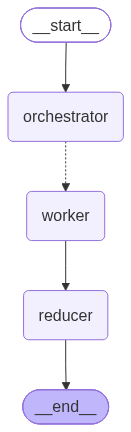

In [45]:
# -----------------------------
# 5) Graph
# -----------------------------
g = StateGraph(State)
g.add_node("orchestrator", orchestrator)
g.add_node("worker", worker)
g.add_node("reducer", reducer)

g.add_edge(START, "orchestrator")
g.add_conditional_edges("orchestrator", fanout, ["worker"])
g.add_edge("worker", "reducer")
g.add_edge("reducer", END)

app = g.compile()

app

In [46]:
out = app.invoke({"topic": "Write a blog on Self Attention", "sections": []})


========== BLOG PLAN GENERATED ==========
Title: Demystifying Self‑Attention: From Theory to Production‑Ready Code
Total sections: 6

1. Why Self‑Attention Matters
Type: intro
Goal: Grasp the core problem self‑attention solves and when it outperforms traditional RNN/CNN pipelines.
Target words: 210
Bullets: ['Contrast sequence‑wise recurrence vs. global token interaction with a 2‑sentence example.', 'Identify workloads (NLP, vision, time‑series) where quadratic token‑wise similarity is justified.', 'Show a quick runtime comparison chart (O(n) vs O(n²)) for a 512‑token input.', 'Explain the intuition behind “query‑key‑value” as a soft lookup table.']

2. Mathematical Foundations of Scaled Dot‑Product Attention
Type: core
Goal: Derive the scaled dot‑product formula and understand each term’s role in stability and expressiveness.
Target words: 340
Bullets: ['Write the full matrix equation\u202f:\u202fAttention(Q,K,V)=softmax(QKᵀ/√dₖ)·V and annotate each symbol.', 'Demonstrate why scaling

In [47]:
print(out["final"])

# Demystifying Self‑Attention: From Theory to Production‑Ready Code

## Why Self‑Attention Matters

### Sequence‑wise recurrence vs. global token interaction  
In a vanilla RNN each token updates the hidden state **sequentially**, so the representation of the third word can only depend on the first two through a chain of hidden vectors. By contrast, self‑attention lets the third word **directly attend** to every other token, enabling a two‑sentence example like “The cat chased the mouse. It escaped.” to resolve “It” by comparing the pronoun to *cat* and *mouse* in a single step.

### Workloads where quadratic token‑wise similarity is justified  
Self‑attention shines when relationships are **dense** and non‑local:  

| Domain | Typical Input | Reason quadratic similarity helps |
|--------|---------------|------------------------------------|
| NLP (e.g., translation, QA) | Sentences ≈ 256–1024 tokens | Long‑range dependencies and coreference |
| Vision (ViT, image segmentation) | Patch